In [4]:
import numpy as np
import cv2
import pysift
from matplotlib import pyplot as plt
import logging
logger = logging.getLogger(__name__)

In [5]:
MIN_MATCH_COUNT = 10

img1 = cv2.imread('box.png', 0)           # queryImage
img2 = cv2.imread('box_in_scene.png', 0)  # trainImage

In [6]:
# Compute SIFT keypoints and descriptors
kp1, des1 = pysift.computeKeypointsAndDescriptors(img1)
kp2, des2 = pysift.computeKeypointsAndDescriptors(img2)

 resized image: (446, 648)
 sigma diff: 1.2489995996796799
 resized image: (768, 1024)
 sigma diff: 1.2489995996796799


In [27]:
print(len(kp1), type(kp1[0]), len(des1), des1[0].shape)
print(len(kp2), kp2[0], len(des2), des2[0].shape)

603 <class 'cv2.KeyPoint'> 603 (128,)
966 < cv2.KeyPoint 0x780d841e22b0> 966 (128,)


In [7]:
# Initialize and use FLANN
FLANN_INDEX_KDTREE = 0
index_params = dict(algorithm = FLANN_INDEX_KDTREE, trees = 5)
search_params = dict(checks = 50)

## FLANN Matcher

Classical feature descriptors (SIFT, SURF, ...) are usually compared and matched using the Euclidean distance (or L2-norm). 

Since SIFT and SURF descriptors represent the histogram of oriented gradient (of the Haar wavelet response for SURF) in a neighborhood, alternatives of the Euclidean distance are histogram-based metrics ( χ2, Earth Mover’s Distance (EMD), ...).

Arandjelovic et al. proposed in [11](https://docs.opencv.org/3.4/d0/de3/citelist.html#CITEREF_Arandjelovic:2012:TTE:2354409.2355123) to extend to the RootSIFT descriptor:

`a square root (Hellinger) kernel instead of the standard Euclidean distance to measure the similarity between SIFT descriptors leads to a dramatic performance boost in all stages of the pipeline.`

Binary descriptors (ORB, BRISK, ...) are matched using the Hamming distance. This distance is equivalent to count the number of different elements for binary strings (population count after applying a XOR operation):

$$ d_{hamming}(a,b)= \sum^{n−1}_{i=0}(a_i \oplus b_i)$$

To filter the matches, Lowe proposed in [[Distinctive image features from scale-invariant keypoints]](https://doi.org/10.1023/B:VISI.0000029664.99615.94) to use a distance ratio test to try to eliminate false matches. The distance ratio between the two nearest matches of a considered keypoint is computed and it is a good match when this value is below a threshold. Indeed, this ratio allows helping to discriminate between ambiguous matches (distance ratio between the two nearest neighbors is close to one) and well discriminated matches. The figure below from the SIFT paper illustrates the probability that a match is correct based on the nearest-neighbor distance ratio test.

In [8]:
flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des1, des2, k=2)

# Lowe's ratio test
good = []
for m, n in matches:
    if m.distance < 0.7 * n.distance:
        good.append(m)

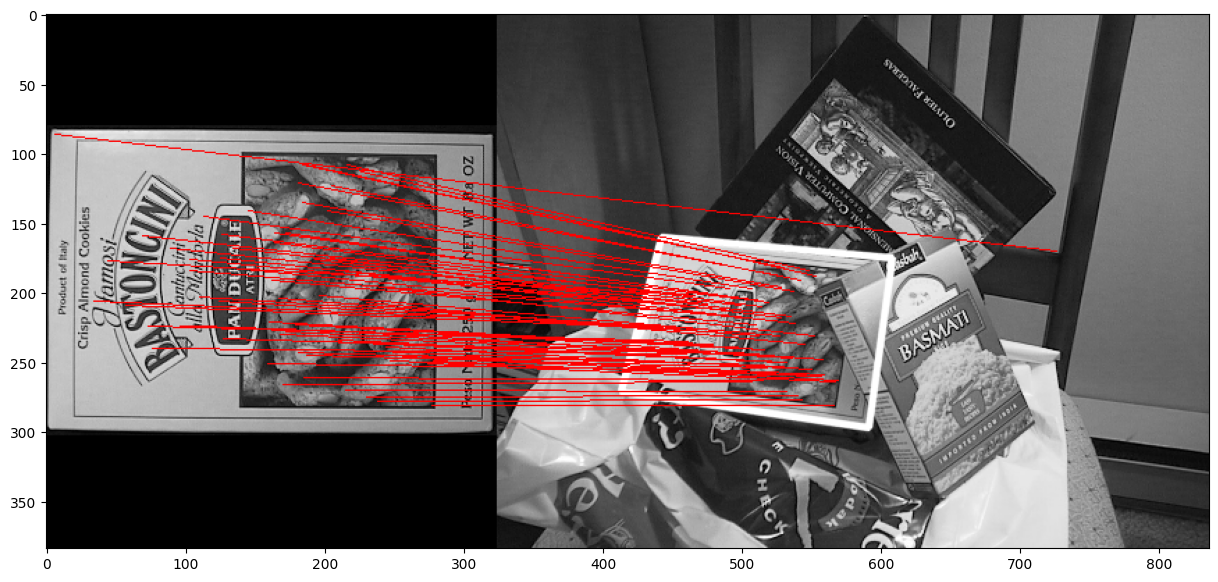

In [10]:
if len(good) > MIN_MATCH_COUNT:
    # Estimate homography between template and scene
    src_pts = np.float32([ kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([ kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)

    M = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)[0]

    # Draw detected template in scene image
    h, w = img1.shape
    pts = np.float32([[0, 0],
                      [0, h - 1],
                      [w - 1, h - 1],
                      [w - 1, 0]]).reshape(-1, 1, 2)
    dst = cv2.perspectiveTransform(pts, M)

    img2 = cv2.polylines(img2, [np.int32(dst)], True, 255, 3, cv2.LINE_AA)

    h1, w1 = img1.shape
    h2, w2 = img2.shape
    nWidth = w1 + w2
    nHeight = max(h1, h2)
    hdif = int((h2 - h1) / 2)
    newimg = np.zeros((nHeight, nWidth, 3), np.uint8)

    for i in range(3):
        newimg[hdif:hdif + h1, :w1, i] = img1
        newimg[:h2, w1:w1 + w2, i] = img2

    # Draw SIFT keypoint matches
    for m in good:
        pt1 = (int(kp1[m.queryIdx].pt[0]), int(kp1[m.queryIdx].pt[1] + hdif))
        pt2 = (int(kp2[m.trainIdx].pt[0] + w1), int(kp2[m.trainIdx].pt[1]))
        cv2.line(newimg, pt1, pt2, (255, 0, 0))
    plt.figure(figsize=(15,10))
    plt.imshow(newimg)
    plt.show()
else:
    print("Not enough matches are found - %d/%d" % (len(good), MIN_MATCH_COUNT))

## Display using `cv2.DrawMatches`

In [17]:
 
#-- Draw matches
img_matches = np.empty((max(img1.shape[0], img2.shape[0]), img1.shape[1]+img2.shape[1], 3), dtype=np.uint8)
matchup_image = cv2.drawMatches(img1, kp1, img2, kp2, good, img_matches, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)


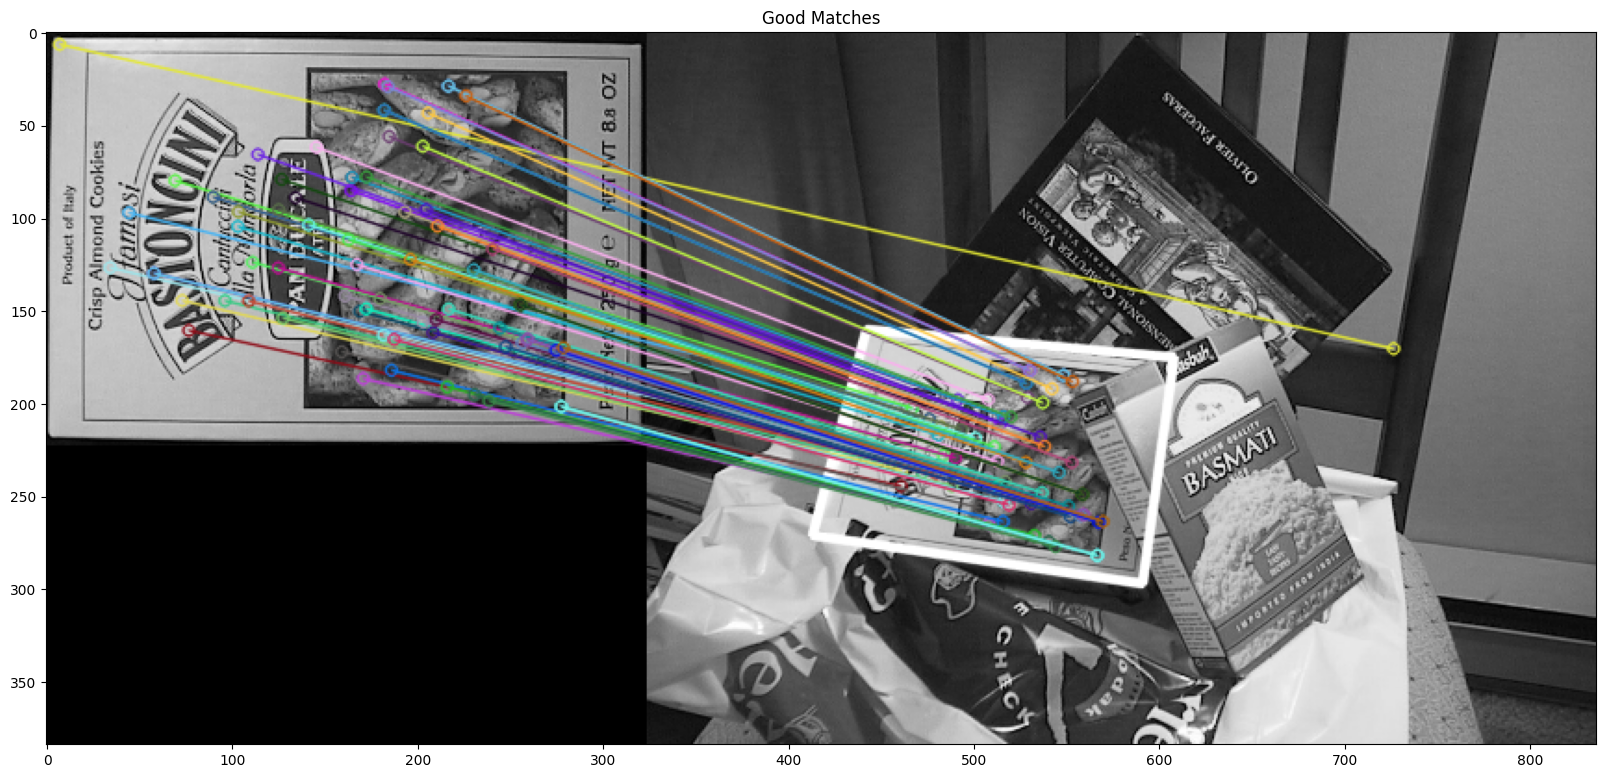

In [35]:
plt.figure(figsize=(20,15))
axesImage = plt.imshow( matchup_image)
axesImage.axes.set_title("Good Matches")
plt.show()